In [1]:
import sys, time, tempfile
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'C' / 'evoca.h').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('repo root (C/evoca.h) not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'python'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evoca_py import EvoCA, LUT_BYTES
import evoca_explore as ee
WS = 'Lineage-co-evolution'
WSDIR = ROOT / 'Research' / WS
SCANS = WSDIR / 'Scans'
T_NOTEBOOK = time.time()
print('repo root:', ROOT)

repo root: /private/tmp/evoca_food-cap-standard


# Lineage-co-evolution: lab notebook

**Question.** Do the CA-rule genome (the 250-bit LUT) and the eating genome (the egene) co-evolve
*adaptively*, or do they just drift together? And can **lineage-level net metabolic return**
(cumulative intake minus cumulative tax, per lineage) separate adaptation from drift?

This is the chronological lab notebook for the workstream. Newest section at the bottom.
Open questions live in [`ISSUES.md`](ISSUES.md) (single source). Finished digests are in
[`digests/`](digests/) (currently [`coevolution-substrate`](digests/coevolution-substrate.ipynb), a
draft). Raw scans (main thread: the 2026-10-23 standard-model rescans):
[`Scans/2026-10-23_pure_evo_egene_on_winners_standard`](Scans/2026-10-23_pure_evo_egene_on_winners_standard/notes.md) (campaign #3),
[`Scans/2026-10-23_3c_coevolution_substrate_standard`](Scans/2026-10-23_3c_coevolution_substrate_standard/notes.md) (#3c);
the recorded legacy-rule originals [`2026-05-17_pure_evo_egene_on_winners`](Scans/2026-05-17_pure_evo_egene_on_winners/) and
[`2026-05-19_3c_coevolution_substrate`](Scans/2026-05-19_3c_coevolution_substrate/notes.md) are used only in the final section;
[`Scans/2026-05-19_8_lineage_coevolution`](Scans/2026-05-19_8_lineage_coevolution/scan.py) (#8, on hold,
no results). Planning docs: [`Research/Lineage-co-evolution/plans/plan-3c-coevolution-substrate.md`](plans/plan-3c-coevolution-substrate.md),
[`Research/Lineage-co-evolution/plans/plan-8-lineage-coevolution.md`](plans/plan-8-lineage-coevolution.md).

**Convention for example runs.** Every example run here is small (N <= 128, <= 3000 steps per phase, seeded) so the
whole notebook executes in a few minutes. Statements marked *observed in this example run* are single-seed
illustrations at small N, **not campaign results**. Recorded campaign results are quoted with their source.

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel. 

**Eating rule.** Everything above the final section uses the **standard model**: the capped mouthful (`food_cap=1`, the A9 fix), under which a cell never eats more food than its site holds. The legacy uncapped rule (`food_cap=0`) let `m_scale x score > 25` overdraw the site, drive `F` negative and drain the next eater's private food; it is unphysical and not part of the model. It matters here: every example run and every row of the #3 and #3c scans has `m_scale` between 1.5 and 3, where the cap can bind. The example runs were re-executed under the standard rule on 2026-10-23 (the earlier stored outputs were legacy-rule). Campaigns #3 and #3c ran the legacy rule; the main thread uses their 2026-10-23 standard-model rescans (same configs, today's code), and the recorded headlines change substantially. The recorded results and a recorded / legacy-now / standard comparison are in the last section, "Legacy rule (`food_cap=0`)".

## Open questions snapshot

The cell below renders [`ISSUES.md`](ISSUES.md) as of the last execution of this notebook. **`ISSUES.md` is the
source**; this is only a snapshot and may be stale.

In [2]:
display(Markdown((ROOT / 'Research' / WS / 'ISSUES.md').read_text()))

# Lineage-co-evolution: issues and directions
_Updated 2026-10-23_

The workstream question has two parts: (1) is there adaptive LUT<->egene *coupling* (co-evolution) or just joint drift, and (2) can lineage-level net metabolic return separate adaptation from drift. H1/D3 address part 2; the #8 redesign is the only direct handle on part 1. Example-run evidence cited below comes from `Lineage-co-evolution.ipynb` (single seed, N<=128, not campaign results), re-executed 2026-10-23 under the standard model (`food_cap=1`). Campaign evidence for #3 and #3c now comes from the 2026-10-23 standard-model rescans; the recorded May results were legacy-rule (`food_cap=0`) results and several do not hold (notebook, last section).

## Decisions needed (N)
- **LIN-D1**: #8 redesign: which fix option, now that D2 exists? (`Research/Lineage-co-evolution/plans/plan-8-lineage-coevolution.md` lists A-F; the board lists old #8 as "superseded by D2 + H1", but D2/H1 answer part 2, not the part-1 coupling question.) Options:
  - *Retire #8*, rely on H1 only. Cheapest; leaves "do LUT and egene changes get retained *jointly*?" untested.
  - **Recommended: Option A (Hamming magnitude of LUT bytes vs egene bytes per surviving edge) with `restricted_mu=1` (the existing toggle, i.e. Option F for free), reusing the harness.** Notebook section 3 shows the binary indicator saturating exactly as 1-exp(-250 mu) (0.918 at 0.01, 0.9995 at 0.03) while Hamming keeps mean 250*mu and nonzero spread, and bulk LUT bytes come from one pointer read, so no per-cell loop. Pure Python, no C change. Add the D2 join as phase 2 (below).
  - Option B (add lut_complexity level change) as a secondary read-out; needs a tiny per-cell accessor (dev).
  - Options C, D, E: heavier; keep in reserve if A shows signal but non-monotone coupling (C) or needs temporal persistence (D).
  - Caveats found in the example run: (a) Spearman(LUT Hamming, egene Hamming) was ~0 at every `mu_lut` there (2026-10-23, standard rule: |rho| <= 0.018; one p = 0.037 of four, not significant after four tests), which is the expected null *and* what unpowered silent-bit noise looks like, so run a power check (inject a synthetic coupling) before the campaign; (b) `restricted_mu=1` changes the Poisson rate to `mu_lut * n_active`, so `mu_lut` must be re-chosen; not tested here.
  - Blocks: any #8 campaign. Does not block H1/D3.
- **LIN-D2**: Lineage unit for H1 when `mu_lut` is productive. D2 keys on the full-genome hash, i.e. a *genotype*. Example run (2026-10-23, standard rule): fraction of live cells sharing a genotype 0.59, 0.14, 0.08, 0.001 at `mu_lut` 0.001, 0.003, 0.01, 0.03; 4 lineages reach 10 births at 0.01 and none at 0.03, so per-hash net return is a per-individual quantity, not a clade property. Options: (a) restrict H1 to `mu_lut` <= ~0.003 where genotypes persist (no dev, but excludes the productive corner used by #3c/#8); (b) clade roll-up in Python along `parent_id` chains from the existing getters (analysis, moderate cost); (c) a C-side clade reducer (dev, only if (b) is too slow). Recommendation: (a) for a first H1 pass plus (b); decide (c) only if needed. Blocks: H1 at the productive corner of the Sec. B sweep.
- **LIN-D3**: Tax basis in the net-return reducer. It counts nominal tax; the dissipation accountant counts tax actually removed. **2026-10-23:** under the standard rule the gap is 0.5% (343,261 vs 341,629 evolving; 343,538 vs 341,937 control, N=96, 3000 steps). The 20-23% gap recorded 2026-10-15 (887,729 vs 738,159; 939,192 vs 763,713) was a legacy-rule effect: the overdraw drained private food, so dying cells could not pay their tax. Options: document the residual bias (cheap), or add an actual-tax column to the reducer (small C change, needs N's gate). Recommendation, revised: document only; add the column only if H1 lineage-level comparisons turn out to be sensitive to a ~0.5% bias. No longer blocks H1/D3.

## Open questions
- **LIN-Q1**: Is there any adaptive LUT<->egene co-evolution at all? **2026-10-23, standard-model rescans:** #3 shows no 3a/3b gap (mean `eg_excess_pc_slope` 22.6 vs 24.0, extinction 3/144 vs 2/144; recorded legacy 17.5 vs 1.7 and 12% vs 46%). In #3c frozen GoL is viable (B 0/10 extinct, recorded 10/10) and the GoL anchors carry late-window egene excess (B +0.97, B' +2.44) as large as the evolved arms (C +1.35, A -0.06). The one surviving coupling signal is C over A from the same substrate: paired slope > 0 in 27/30, mean +0.44 (recorded 22/30, +0.62). A legacy rerun with today's code (`Scans/2026-10-23_legacy_now_subset`) reproduces the recorded extinctions, so the change is the rule. The direct test (#8) has produced no data (`Scans/2026-05-19_8_lineage_coevolution/` has `scan.py` only). Unanswered.
- **LIN-Q2**: Is the #3c plateau real or a saturation of the cumulative-excess metric? **2026-10-23, standard rescan:** late-window slopes are positive for C (+1.35), B (+0.97) and B' (+2.44) and ~0 for A (-0.06), so there is no uniform plateau; but whole-phase-2 slopes are negative in A and C because `eg_excess_pc` carries ~9.4e4 over the switch and decays in the first 2000 ticks (early-window slope -27). In the N=96 replica every arm boom-busts (seed 1: ~500 to ~8,500 cells, period ~350 steps). The shadow is not re-baselined at the switch (follow-up F1 in `research_board_archival.md`), and that transient now dominates the whole-phase slope. Needs F1 or a lineage-based read-out to settle.
- **LIN-Q3**: Raw net return is set by the shared population dynamics, not the genotype. **2026-10-23, standard rule:** the #3c regime at N=96 boom-busts (period ~150 steps); coexisting control genotypes have the same per-capita net-rate time course (about -0.02 to +0.06, in phase), and intake is 85% of the food source (352,853 of 414,720; overflow 63,146). (Under the legacy rule the lattice was saturated, intake equalled the source and the control's dominant genotype sat at `food_inc*N^2/pop - tax` = -0.020.) So what is the right *relative* fitness quantity for H1: net return relative to the same-time population mean, per-lineage growth rate vs shadow (checkpoint Sec. H step 2), or births per capita? D2 output alone does not answer adaptive-vs-drift.
- **LIN-Q4** (resolved 2026-10-23): Frozen-GoL (3b/B) viability and the shadow's effect on the real run. With today's code, config 253 (N=128, seed 0) gives the identical population trajectory with and without the neutral shadow (notebook section 1 check): the shadow has its own RNG stream since 2026-10-15, so shadow-on and shadow-off runs are the same experiment. Under the standard rule frozen GoL is viable (3b 2/144 extinct, #3c B 0/10); the coin-flip viability seen before was a legacy-rule, shared-RNG observation.
- **LIN-Q5**: How often does the `dyn_excess_pc` artifact fire? **2026-10-23:** never, in the standard #3c rescan (0/30 A runs > 50, median -1.36) and in the N=96 replica (0/4). Recorded (legacy): 21/30, median +249. The legacy rule with today's code reproduces it (2 of 3 A runs: +413, +7, +484), so in this regime it is a legacy-rule phenomenon tied to the saturated frozen-rich population (legacy A min_pop ~40,000 at N=256 vs ~8,000 standard). Open: whether it can still fire under the standard rule in a regime that saturates. Keep the rule "only interpret `dyn_excess_pc` where `mu_lut>0`" until that is checked.
- **LIN-Q6** (resolved for the main thread 2026-10-23): Provenance gap in campaign #3. The standard rescan `Scans/2026-10-23_pure_evo_egene_on_winners_standard/` has `notes.md`, `scan_config.json` and `run.log`, and its rows carry `param_food_cap`. The recorded legacy scan `2026-05-17_pure_evo_egene_on_winners/` still has neither file; it is now used only in the notebook's legacy section, so no fix is needed unless recipes are built from it.

## Next directions
- **LIN-N1**: D3 punctuation detector: lineage net-return dip-then-staircase at Negene increments, single unforced run. Kind: needs dev (analysis). Unblocked by the D2 merge. Gaps found: (i) a Negene change creates a *new* hash row, so the detector must link child hash to parent hash; `lineage_parent_hash` gives the parent's hash per newborn but no per-cell full-genome hash accessor exists, and no parent-hash link table is exposed; (ii) `last_step` is only as current as the last `lineage_return_update()`, so trajectories need periodic sampling (longevity resolution = sampling interval); (iii) per LIN-Q3, detect the step in a *relative* quantity. Checkpoint action D3; N's 2026-07-19 note on Sec. D proposes punctuation as a random-slot-addition event (slot activation alone may have negligible effect).
- **LIN-N2**: H1 adaptive-vs-drift program on the Sec. B `food_inc/tax` sweep: lineage net return + A_new + shadow-beating lineage count, with the falsifier (raw activity inverted-U too means the drift-collapse story is wrong). Kind: campaign + analysis. Blockers: G1 (A_new) merged; LIN-D2 (lineage unit), LIN-D3 (tax basis), LIN-Q3 (relative fitness). Checkpoint action H1 (shared with Activity-metrics).
- **LIN-N3**: #8 relaunch per the LIN-D1 outcome: synthetic-coupling power check first, then 2 arms x 8 seeds as in the original spec with `mu_lut` retuned if `restricted_mu=1`. Kind: campaign (pure Python harness exists, flawed observable only). Blocked on LIN-D1.
- **LIN-N4**: Join D2 to the #8 edges: use the child genotype's reducer `births` (reproductive success, not `net`, given LIN-Q3) as the outcome and test the dLUT x dEgene interaction beyond additive effects, with a permutation null. Kind: needs dev (analysis). Blocked on LIN-D1, LIN-D2.
- **LIN-N5**: Re-baseline the shadow at a phase switch (F1) and rerun a #3c-style A/C comparison with lineage read-outs instead of `dyn_excess_pc`. Kind: needs dev (small C change) then campaign. Not started; N to decide priority. 2026-10-23: more pressing under the standard rule, where the excess carried over the switch (~9.4e4) dominates the whole-phase-2 slope.
- **LIN-N6**: Finish the `coevolution-substrate` digest (draft in `digests/`). 2026-10-23: switched to the standard rescans and its headline rewritten (the GoL-death confound and the dyn artifact do not hold under the standard rule); still a draft, approval-gated. Kind: doc/analysis, no blocker.

## Parked
- Option C/D/E variants of the #8 observable: revisit only if LIN-D1's Option A shows signal that is non-monotone or temporal.
- Evolving-rate genes (`mu-genome`, A2) as a co-evolution lever: A2 storage scaffold merged 2026-10-15 (`get/set_mu_lut_gene`; inherited, not yet mutated or read); the evolvable-rate follow-on is infrastructure work, outside this workstream until it lands.
- Recipes: none exported; the notebook's example runs are scripted (seeded) rather than saved as `.evoca`, because several need mid-run switches (#3c) or post-init `enable_lineage()` that the recipe format does not appear to capture (not checked in detail).


In [3]:
# ---- shared helpers for the example runs ----
# rgb(sim, colormode): headless lattice frame (N, N, 3) uint8; params_from_row(row): scan row -> build_sim params
from evoca_nb import rgb, slope, params_from_row   # shared notebook helpers: python/evoca_nb.py

def mean_negene(sim):
    alive = sim.get_alive() == 1
    if not alive.any():
        return 0.0
    return float(np.unpackbits(sim.get_active()[alive][:, None], axis=1).sum(1).mean())

def sample_basic(sim):
    """One time-series sample: pop, egene excess (cumulative), dyn excess, mean Negene."""
    sim._lib.evoca_eg_activity_update()
    alive = sim.get_alive() == 1
    return dict(pop=int(alive.sum()), eg_excess=float(sim.eg_excess_pc()),
                dyn_excess=float(sim.dyn_excess_pc()), negene=mean_negene(sim))

## 1. Campaign #3 (2026-05-17): egene scan on the LUT-only winners, 3a (LUT co-evolving) vs 3b (LUT frozen)

**Question.** Take the top-12 LUT-only (#2) regimes. Does adding egene evolution on top of them produce egene-level
selection (eg-excess) and does it depend on the LUT still evolving? **3a** keeps the winner's `mu_lut`; **3b** sets
`mu_lut=0` (LUT frozen as GoL) and varies only the egene knobs.
Scan (main thread): [`Scans/2026-10-23_pure_evo_egene_on_winners_standard/`](Scans/2026-10-23_pure_evo_egene_on_winners_standard/notes.md), the
standard-model rescan of the recorded [`2026-05-17_pure_evo_egene_on_winners`](Scans/2026-05-17_pure_evo_egene_on_winners/) (288 rows, N=256,
8000 steps, seed 0, shadow on; same configs, checked column by column; bases still read from the original LUT-only scan). The example runs below
rebuild each configuration from its `results.csv` row via `evoca_explore.build_sim`.

**Recorded finding (legacy rule, see the last section):** 3a >> 3b (eg-excess ~20 vs ~6), strong apparent co-dependence, **but confounded**:
3b froze *GoL*, not an evolved LUT, and 46% of 3b runs went extinct. Under the standard rule this does not hold (below).

In [4]:
d3 = pd.read_csv(SCANS / '2026-10-23_pure_evo_egene_on_winners_standard' / 'results.csv')   # standard-model rescan
summ = d3.groupby('mode').agg(n=('mode', 'size'), extinct_frac=('extinct', 'mean'),
                              eg_excess_pc_slope_mean=('eg_excess_pc_slope', 'mean'),
                              alive_density_mean=('alive_density_mean', 'mean')).round(3)
print('Campaign #3, standard-model rescan, by mode (N=256, 8000 steps):')
display(summ)
b = d3.groupby(['base_cfg', 'mode']).agg(extinct=('extinct', 'mean'), eg_slope=('eg_excess_pc_slope', 'mean')).unstack()
print('3a > 3b mean eg_excess_pc_slope on', int((b['eg_slope']['3a'] > b['eg_slope']['3b']).sum()), 'of', len(b), 'base regimes')
display(b.round(2).T)

Campaign #3, standard-model rescan, by mode (N=256, 8000 steps):


,n,extinct_frac,eg_excess_pc_slope_mean,alive_density_mean
mode,,,,
3a,144,0.021,22.614,0.231
3b,144,0.014,23.961,0.222


3a > 3b mean eg_excess_pc_slope on 5 of 12 base regimes


base_cfg          0      1      2      3     4     5      6      7      8   \
         mode                                                                
extinct  3a     0.00   0.00   0.00   0.00   0.0  0.25   0.00   0.00   0.00   
         3b     0.00   0.00   0.00   0.00   0.0  0.17   0.00   0.00   0.00   
eg_slope 3a     8.44  28.12  28.36  28.94  28.7  2.15  29.44  16.05  23.24   
         3b    11.22  31.59  27.70  32.81  27.7  2.10  27.70  18.42  26.39   

base_cfg          9      10     11  
         mode                       
extinct  3a     0.00   0.00   0.00  
         3b     0.00   0.00   0.00  
eg_slope 3a    24.21  37.44  16.28  
         3b    27.03  35.24  19.64

**Example runs.** Two matched 3a/3b pairs from `results.csv` (same base regime and egene knobs; 3b has `mu_lut=0`):
config 252/253 (base regime 10) and 236/237 (base regime 9, where 3b went extinct in the recorded legacy-rule scan; it survives in the standard rescan).
Run at **N=128, 3000 steps, seed 0** with lineage tracking and the neutral shadow on.

In [5]:
d3i = d3.set_index('config_idx')
N3, T3 = 128, 3000
ex3 = {}
t0 = time.time()
for label, cfg in [('3a cfg252', 252), ('3b cfg253', 253), ('3a cfg236', 236), ('3b cfg237', 237)]:
    sim = ee.build_sim(params_from_row(d3i.loc[cfg]), N=N3, seed=0)
    sim.enable_lineage(); sim.neutral_enable()      # after init: current cells become founders
    rows = []
    for i in range(T3):
        sim.step()
        if (i + 1) % 100 == 0:
            s = sample_basic(sim); s['t'] = i + 1; rows.append(s)
    ts = pd.DataFrame(rows)
    intake, tax = sim.lineage_return_totals()
    ex3[label] = dict(cfg=cfg, ts=ts, frame=rgb(sim, 0), n_lin=sim.get_lineage_return().size,
                      intake=intake, tax=tax)
    sim.free()
print(f'{time.time()-t0:.1f}s')

rec = []
for label, e in ex3.items():
    r = d3i.loc[e['cfg']]
    ts = e['ts']
    rec.append({'run': label, 'scan extinct (N=256)': bool(r['extinct']),
                'scan alive_density_mean': round(r['alive_density_mean'], 3),
                'scan eg_excess_pc_final / N^2': round(r['eg_excess_pc_final'] / 256**2, 2),
                'example extinct (N=128)': bool(ts['pop'].min() == 0),
                'example alive density, last': round(ts['pop'].iloc[-1] / N3**2, 3),
                'example eg_excess_pc / N^2, t=3000': round(ts['eg_excess'].iloc[-1] / N3**2, 2),
                'example mean Negene, t=3000': round(ts['negene'].iloc[-1], 2),
                'lineages (hash-keyed)': e['n_lin']})
display(pd.DataFrame(rec).set_index('run'))

4.0s


,scan extinct (N=256),scan alive_density_mean,scan eg_excess_pc_final / N^2,example extinct (N=128),"example alive density, last","example eg_excess_pc / N^2, t=3000","example mean Negene, t=3000",lineages (hash-keyed)
run,,,,,,,,
3a cfg252,False,0.250,10.83,False,0.255,4.94,1.02,101278
3b cfg253,False,0.236,6.90,False,0.304,3.46,1.14,4477
3a cfg236,False,0.193,3.80,False,0.235,2.13,1.75,109743
3b cfg237,False,0.195,10.05,False,0.198,1.98,2.21,14508


In [6]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = ee.build_sim(params_from_row(d3i.loc[252]), N=256, seed=0)   # or configs 253, 236, 237
# run_with_controls(sim, cell_px=2, probes={'eg_activity': True, 'dyn_activity': True, 'ts': True})

In [7]:
# LIN-Q4 check: does enabling the neutral shadow change the real run? (config 253, N=128, seed 0, 3000 steps)
q4 = {}
for shadow in (False, True):
    sim = ee.build_sim(params_from_row(d3i.loc[253]), N=N3, seed=0)
    sim.enable_lineage()
    if shadow:
        sim.neutral_enable()
    pops = []
    for i in range(T3):
        sim.step()
        if (i + 1) % 500 == 0:
            pops.append(int(sim.get_alive().sum()))
    q4[shadow] = pops
    sim.free()
print('alive cells every 500 steps, shadow off:', q4[False])
print('alive cells every 500 steps, shadow on: ', q4[True])
print('identical' if q4[False] == q4[True] else 'DIFFERENT')

alive cells every 500 steps, shadow off: [2507, 3450, 4285, 4591, 4850, 4987]
alive cells every 500 steps, shadow on:  [2507, 3450, 4285, 4591, 4850, 4987]
identical


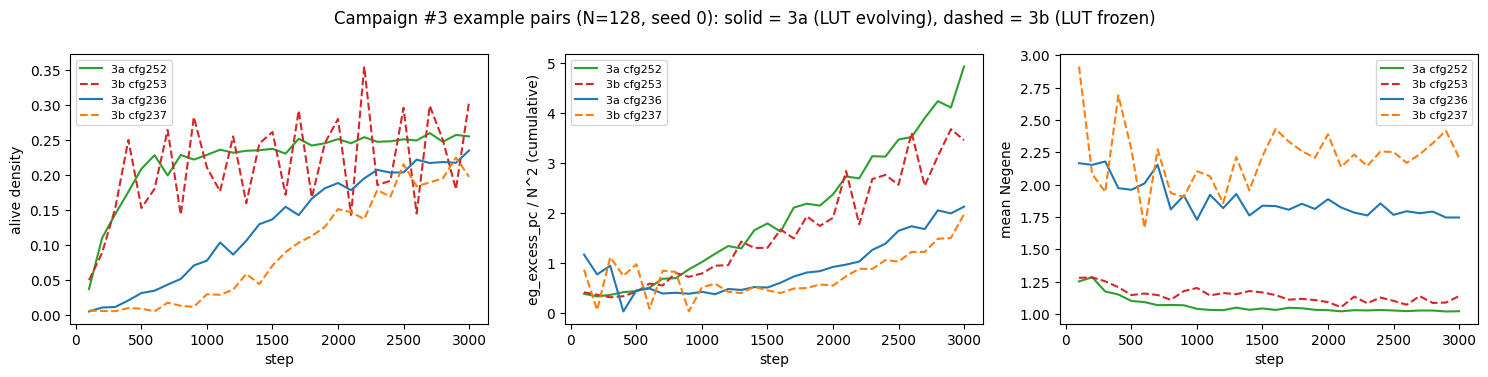

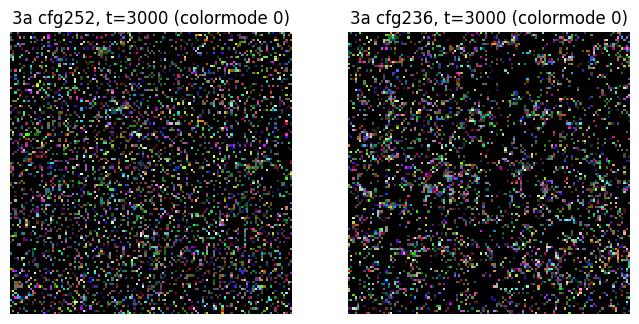

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
col = {'3a cfg252': 'C2', '3b cfg253': 'C3', '3a cfg236': 'C0', '3b cfg237': 'C1'}
for label, e in ex3.items():
    ts = e['ts']; ls = '-' if label.startswith('3a') else '--'
    ax[0].plot(ts.t, ts['pop'] / N3**2, ls, c=col[label], label=label)
    ax[1].plot(ts.t, ts['eg_excess'] / N3**2, ls, c=col[label], label=label)
    ax[2].plot(ts.t, ts['negene'], ls, c=col[label], label=label)
ax[0].set_ylabel('alive density'); ax[1].set_ylabel('eg_excess_pc / N^2 (cumulative)'); ax[2].set_ylabel('mean Negene')
for a in ax: a.set_xlabel('step'); a.legend(fontsize=8)
fig.suptitle('Campaign #3 example pairs (N=128, seed 0): solid = 3a (LUT evolving), dashed = 3b (LUT frozen)')
fig.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, lab in zip(ax, ['3a cfg252', '3a cfg236']):
    a.imshow(ex3[lab]['frame'], interpolation='nearest'); a.set_title(lab + ', t=3000 (colormode 0)'); a.axis('off')
plt.show()

**Observations.**
- **Standard rescan (N=256, 8000 steps):** freezing the LUT at GoL costs neither viability nor egene excess. Extinction is 3/144 (3a) vs 2/144 (3b),
  all in base regime 5. Mean `eg_excess_pc_slope` is 22.6 (3a) vs 24.0 (3b), medians 10.6 vs 15.4, and 3a beats 3b on only 5 of 12 base regimes.
  Mean alive density 0.231 vs 0.222. The recorded "3a >> 3b" (17.5 vs 1.7, extinction 12% vs 46%) was a legacy-rule result; see the last section.
- *Observed in these example runs, N=128, seed 0, not a campaign result:* all four runs survive, as in the rescan. Each 3a/3b pair reaches similar
  `eg_excess_pc / N^2` at t=3000 (252/253: 4.94 vs 3.46; 236/237: 2.13 vs 1.98). The frozen-GoL run 253 oscillates (alive density ~0.15-0.35) where its
  3a twin settles near 0.25. Mean Negene at t=3000 is 1.0-1.1 (252, 253), 1.75 (236) and 2.2 (237); no staircase is resolvable at 100-step sampling (see 4c).
  The 3b runs have far fewer hash-lineages (4,477 and 14,508 vs ~100,000) because only the egene varies.
- **LIN-Q4 (shadow perturbs the run):** with today's code it does not. Config 253 gives the identical population trajectory with and without the neutral shadow
  (check cell above); the shadow has had its own RNG stream since 2026-10-15. The earlier observation (253 extinct only with the shadow on) was made before that fix
  and under the legacy rule.
- Absolute eg-excess depends on N and run length (the table divides by N^2 for a rough comparison); only orderings are comparable with the scan.

**Directions that came out of it (2026-05).** The 3b arm froze GoL, not an evolved substrate, so the recorded gap conflated "freezing hurts" with
"GoL is a poor substrate". -> campaign #3c. Under the standard rule there is no gap to explain.

## 2. Campaign #3c (2026-05-19): evolve LUT-only, then freeze or keep co-evolving, while egene evolves

**Question.** Separate *substrate quality* from *freezing per se*. Single continuous sim: phase 1 evolves the LUT only
(3000 ticks); at the switch the rule is frozen (**A**) or left co-evolving (**C**) from a byte-identical shared substrate;
egene mutation is on in phase 2 (8000 ticks). **B** = frozen GoL, **B'** = GoL pre-run 100 ticks then frozen (anchors).
Regime (both phases): `m_scale=3.0, food_inc=0.015, tax=0.035, gdiff=0.06`.
Scan (main thread): [`Scans/2026-10-23_3c_coevolution_substrate_standard/`](Scans/2026-10-23_3c_coevolution_substrate_standard/notes.md), the
standard-model rescan of the recorded [`2026-05-19_3c_coevolution_substrate`](Scans/2026-05-19_3c_coevolution_substrate/notes.md) (80 rows, same protocol); spec
[`Research/Lineage-co-evolution/plans/plan-3c-coevolution-substrate.md`](plans/plan-3c-coevolution-substrate.md); digest
[`digests/coevolution-substrate.ipynb`](digests/coevolution-substrate.ipynb) (draft).

**Recorded finding (legacy rule, see the last section)** (`notes.md`): the #3 gap is **mostly a GoL-substrate viability collapse**, not a clean synergy: B is 10/10
extinct; B' is viable but shows flat-zero egene excess. With the substrate byte-identical, co-evolving (C) beats freezing (A)
only modestly but consistently (paired C-A `eg_excess_pc` slope > 0 in 22/30, mean +0.6); absolute egene signal is weak
(|slopes| <~ 1 vs #1's 20-135) and plateaued by ticks 7-8k. **Caveat:** arm A's `dyn_excess_pc_slope ~ +335` is an artifact of
`mu_lut=0` on a rich evolved substrate (the dyn neutral baseline collapses), so `dyn_excess_pc` is uninterpretable there. Under the standard rule both parts change (below).

In [9]:
c3 = pd.read_csv(SCANS / '2026-10-23_3c_coevolution_substrate_standard' / 'results.csv')   # standard-model rescan
rec3c = c3.groupby('arm').agg(n=('arm', 'size'), extinct=('extinct', 'sum'),
                              eg_excess_pc_slope=('eg_excess_pc_slope', 'mean'),
                              dyn_excess_pc_slope=('dyn_excess_pc_slope', 'mean'),
                              determinism_ok=('determinism_ok', lambda s: s.dropna().astype(bool).all())
                              ).round(2).reindex(['A', 'C', 'B', "B'"])
print('#3c standard-model rescan by arm (N=256, 3000+8000 ticks, 10 seeds x 3 phase-1 mu_lut):')
display(rec3c)
A_ = c3[c3.arm == 'A'].set_index(['seed', 'param_mu_lut_p1']); C_ = c3[c3.arm == 'C'].set_index(['seed', 'param_mu_lut_p1'])
pd_ = C_['eg_excess_pc_slope'] - A_['eg_excess_pc_slope']
print(f'paired C - A eg_excess_pc_slope: > 0 in {int((pd_ > 0).sum())}/{len(pd_)}, mean {pd_.mean():+.2f}, median {pd_.median():+.2f}')
print('A runs with dyn_excess_pc_slope > 50:', int((A_['dyn_excess_pc_slope'] > 50).sum()), 'of', len(A_),
      f"(median {A_['dyn_excess_pc_slope'].median():+.2f}, max {A_['dyn_excess_pc_slope'].max():+.2f})")
display(c3.groupby('arm')[['eg_excess_pc_slope_early', 'eg_excess_pc_slope_late', 'min_pop', 'final_pop']].mean().round(2).reindex(['A', 'C', 'B', "B'"]))

#3c standard-model rescan by arm (N=256, 3000+8000 ticks, 10 seeds x 3 phase-1 mu_lut):


,n,extinct,eg_excess_pc_slope,dyn_excess_pc_slope,determinism_ok
arm,,,,,
A,30,0,-1.63,-1.33,True
C,30,0,-1.19,3.56,True
B,10,0,0.69,0.00,True
B',10,0,1.44,0.00,True


paired C - A eg_excess_pc_slope: > 0 in 27/30, mean +0.44, median +0.46
A runs with dyn_excess_pc_slope > 50: 0 of 30 (median -1.36, max +0.90)


,eg_excess_pc_slope_early,eg_excess_pc_slope_late,min_pop,final_pop
arm,,,,
A,-27.18,-0.06,8029.67,28949.73
C,-27.58,1.35,6725.03,13822.13
B,-7.59,0.97,2496.00,18314.40
B',0.91,2.44,2568.40,9960.70


**Example runs.** A scaled-down replica (N=96, phase 1 = 2000, phase 2 = 2000, phase-1 `mu_lut=0.03`, seeds 0-3), same
fork-by-determinism design as the scan (A and C re-run phase 1 with the same seed, and the LUT hashes at the switch are asserted
equal). Plus one B and one B' run (seed 0). Lineage tracking is on; the shadow is **not** re-baselined at the switch (that is
follow-up F1), so slopes are fit over phase 2 only, as in the scan.

In [10]:
REG3C = dict(m_scale=3.0, food_inc=0.015, tax=0.035, gdiff=0.06)

def new_3c(N, seed, mu_lut, lineage=True):
    s = ee.build_sim(dict(REG3C, mu_lut=mu_lut, mu_egene=0.0, mu_egenome=0.0, tax_per_egene=0.0),
                     N=N, seed=seed, lineage=lineage)
    s.neutral_enable()
    return s

def run_3c(arm, seed, N=96, p1=2000, p2=2000, p1mu=0.03, keep_frame=False):
    mu1 = {'A': p1mu, 'C': p1mu, 'B': 0.0, "B'": 0.0}[arm]
    pre = 100 if arm == "B'" else p1
    s = new_3c(N, seed, mu1)
    for _ in range(pre):
        s.step()
    lh = s.get_lut_hashes().copy()
    if arm in ('A', 'B', "B'"):
        s.update_mu_lut(0.0)
    s.update_mu_egene(0.01); s.update_mu_egenome(0.01)
    rows = []
    for i in range(p2):
        s.step()
        if (i + 1) % 100 == 0:
            r = sample_basic(s); r['t'] = i + 1; rows.append(r)
    ts = pd.DataFrame(rows)
    out = dict(arm=arm, seed=seed, lh=lh, ts=ts, n_lineages=s.get_lineage_return().size,
               intake_tax=s.lineage_return_totals(),
               frame=rgb(s, 0) if keep_frame else None)
    s.free()
    return out

t0 = time.time()
runs3c = {}
for seed in range(4):
    for arm in ('A', 'C'):
        runs3c[(arm, seed)] = run_3c(arm, seed, keep_frame=(seed == 1))
runs3c[('B', 0)] = run_3c('B', 0)
runs3c[("B'", 0)] = run_3c("B'", 0)
print(f'{time.time()-t0:.1f}s')

rows = []
for (arm, seed), r in runs3c.items():
    ts = r['ts']
    rows.append(dict(arm=arm, seed=seed, min_pop=int(ts['pop'].min()), final_pop=int(ts['pop'].iloc[-1]),
                     eg_excess_slope=round(slope(ts.t, ts.eg_excess), 1),
                     dyn_excess_slope=round(slope(ts.t, ts.dyn_excess), 1),
                     dyn_excess_final=round(ts.dyn_excess.iloc[-1])))
tab = pd.DataFrame(rows)
display(tab.set_index(['arm', 'seed']))
for seed in range(4):
    assert np.array_equal(runs3c[('A', seed)]['lh'], runs3c[('C', seed)]['lh']), 'shared-substrate fork broken'
print('determinism: A and C LUT hashes identical at the switch for all 4 seeds')
pa = tab[tab.arm == 'A'].set_index('seed').eg_excess_slope
pc = tab[tab.arm == 'C'].set_index('seed').eg_excess_slope
print('paired C - A eg_excess slope:', (pc - pa).round(1).to_dict())

15.8s


,,min_pop,final_pop,eg_excess_slope,dyn_excess_slope,dyn_excess_final
arm,seed,,,,,
A,0,827,1135,-21.4,-1.2,15506
C,0,686,686,-24.8,5.2,48828
A,1,462,2184,-41.8,-0.0,6123
C,1,579,1370,-31.4,3.2,19821
A,2,431,515,-15.4,1.8,23038
C,2,686,686,-15.4,2.5,45674
A,3,539,761,-24.4,-0.1,17473
C,3,391,1176,-34.7,4.6,26236
B,0,238,284,-4.1,0.0,0


determinism: A and C LUT hashes identical at the switch for all 4 seeds
paired C - A eg_excess slope: {0: -3.4, 1: 10.4, 2: 0.0, 3: -10.3}


In [11]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# (the notebook switches to phase 2 after 2000 steps: mu_egene = mu_egenome = 0.01, and mu_lut -> 0 for arm A; there is no widget for that switch, so re-run the steps by hand or use s.update_mu_* while paused)
# from controls import run_with_controls
# s = new_3c(256, 1, 0.03)   # phase 1 of arm A/C (mu_lut=0.03, egene frozen)
# run_with_controls(s, cell_px=2, probes={'eg_activity': True, 'dyn_activity': True, 'ts': True})

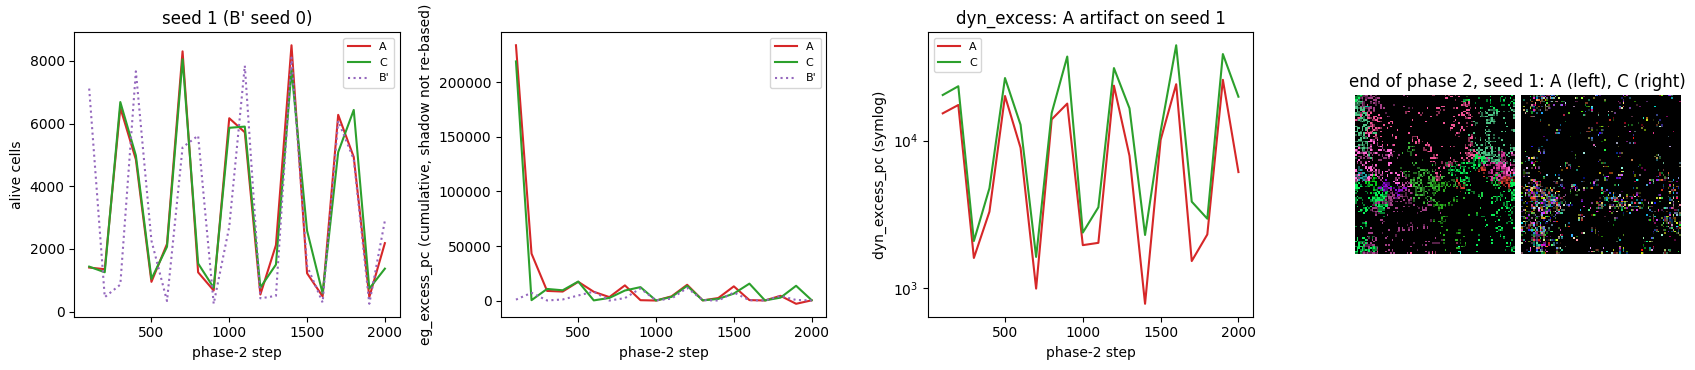

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for arm, c in (('A', 'C3'), ('C', 'C2')):
    ts = runs3c[(arm, 1)]['ts']
    ax[0].plot(ts.t, ts['pop'], c=c, label=arm); ax[1].plot(ts.t, ts.eg_excess, c=c, label=arm)
    ax[2].plot(ts.t, ts.dyn_excess, c=c, label=arm)
for arm, c in (("B'", 'C4'),):
    ts = runs3c[(arm, 0)]['ts']
    ax[0].plot(ts.t, ts['pop'], c=c, ls=':', label=arm); ax[1].plot(ts.t, ts.eg_excess, c=c, ls=':', label=arm)
ax[2].set_yscale('symlog')
ax[0].set_ylabel('alive cells'); ax[1].set_ylabel('eg_excess_pc (cumulative, shadow not re-based)')
ax[2].set_ylabel('dyn_excess_pc (symlog)')
for a in ax[:3]: a.set_xlabel('phase-2 step'); a.legend(fontsize=8)
ax[0].set_title('seed 1 (B\' seed 0)'); ax[2].set_title('dyn_excess: A artifact on seed 1')
ax[3].imshow(np.hstack([runs3c[('A', 1)]['frame'], np.full((96, 4, 3), 255, np.uint8), runs3c[('C', 1)]['frame']]),
             interpolation='nearest')
ax[3].set_title('end of phase 2, seed 1: A (left), C (right)'); ax[3].axis('off')
fig.tight_layout(); plt.show()

**Observations.**
- **Standard rescan (N=256):** no arm goes extinct; plain frozen GoL (B) is viable in 10/10 (recorded legacy: 10/10 extinct). `determinism_ok` holds on all 30 A/C pairs.
- **The GoL anchors carry egene excess.** Mean `eg_excess_pc_slope` over phase 2: B +0.69, B' +1.44, against A -1.63 and C -1.19. In the late window (last 2000 ticks):
  B +0.97, B' +2.44, C +1.35, A -0.06. So a frozen GoL substrate supports at least as much egene excess as a frozen or co-evolving evolved substrate.
  The "GoL-substrate death confound" does not exist under the standard rule.
- **C vs A.** Paired C-A `eg_excess_pc_slope` > 0 in 27/30, mean +0.44, median +0.46, about the same at each phase-1 `mu_lut` (+0.54, +0.43, +0.36 at 0.01, 0.03, 0.06).
  In the late window C-A > 0 in 20/30, mean +1.41. So keeping the rule co-evolving still beats freezing it, modestly and consistently (recorded: 22/30, mean +0.6).
- **Whole-phase-2 slopes are negative in A and C** because `eg_excess_pc` carries a large value over the switch (mean ~9.4e4 at the switch, by the scan's
  `eg_excess_pc_switch`) and falls during the first 2000 ticks (early-window slope -27 in both). That is follow-up F1 (the shadow is not re-baselined at the switch);
  the late-window slopes are the cleaner read.
- **No `dyn_excess_pc` artifact.** 0 of 30 A runs have `dyn_excess_pc_slope` > 50 (median -1.36, max +0.90; recorded legacy: 21/30, median +249).
  A legacy-rule rerun with today's code reproduces the artifact (last section), so in this regime it is a legacy-rule phenomenon. Under the standard rule the
  A populations boom and bust (mean min 8,030, final 28,950 cells) instead of sitting saturated (recorded legacy: 21,723 and 48,949). The rule "only interpret
  `dyn_excess_pc` where `mu_lut > 0`" stays as a precaution; this scan does not show the artifact is absent elsewhere.
- *Observed in this example run (N=96, 4 seeds, not a campaign result):* the shared-substrate fork is bit-identical at the switch for all four seeds. All arms survive,
  B included (min 238 cells). Populations boom and bust in every arm (seed 1: ~500 to ~8,500 cells, period ~350 steps, with A, C and B' roughly in phase).
  `eg_excess_pc` starts phase 2 at ~2.2e5 (seed 1) and falls to near zero within ~300 steps, so every A and C phase-2 slope is negative (-15 to -42) and the
  paired C-A slopes (-3.4, +10.4, 0.0, -10.3) are noise around that transient. No A run shows the dyn artifact (slopes -1.2 to +1.8).

**Directions that came out of it (2026-05).** The decisive clean test is the **direct** one: read the lineage field and ask whether LUT changes and
egene changes are *jointly retained* beyond independent mutation, with no shadow model. -> campaign #8.

## 3. Campaign #8 (2026-05-19, ON HOLD): direct lineage co-evolution metric and the binary-indicator degeneracy

**Question.** At the mutation step, LUT flips and egene changes are drawn by independent passes (`C/evoca.c` mutation code), so across
reproduction edges they are independent by construction. Any (dLUT, dEgene) association among **surviving** edges is selection
retaining co-adapted pairs: a direct, shadow-free co-evolution test. Spec and the 6 fix options (A-F):
[`Research/Lineage-co-evolution/plans/plan-8-lineage-coevolution.md`](plans/plan-8-lineage-coevolution.md). Harness (machinery built, never produced a
`results.csv`): [`Scans/2026-05-19_8_lineage_coevolution/scan.py`](Scans/2026-05-19_8_lineage_coevolution/scan.py).

**Recorded flaw (smoke test, N=64):** with `LUT_BITS=250`, `P(>=1 flip) = 1-exp(-250 mu_lut)` = 0.918 at 0.01, 0.9995 at 0.03.
The binary indicator "LUT hash changed?" saturates at every productive `mu_lut`, so phi ~ 0 trivially. Campaign put **on hold**.

**Example run.** Rebuild the edge table the way the harness does (lineage on from `init`, snapshot `(birth_id, parent_id, LUT bytes, egene
bytes)` every S=4 steps after a warm-up, reconstruct parent->child edges, keep surviving edges), but record **LUT bytes and egene bytes**,
not just hashes, so both the binary indicator and the Option A magnitude (Hamming distance) can be computed from the same edges.
N=64, warm-up 300, window 600, `mu_egene=mu_egenome=0.01`, 4 values of `mu_lut`.

In [13]:
from scipy.stats import spearmanr
_SLOT = np.arange(8, dtype=np.uint8)
_POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.int32)

def egene_bytes(sim):
    """Per-cell egene identity bytes: active mask || 8 slot values || 8 slot masks (inactive slots zeroed)."""
    act = sim.get_active().ravel().astype(np.uint8)
    val = sim.get_egenes().reshape(-1, 8).astype(np.uint8)
    msk = sim.get_egenes_mask().reshape(-1, 8).astype(np.uint8)
    on = ((act[:, None] >> _SLOT) & 1).astype(bool)
    return np.concatenate([act[:, None], np.where(on, val, 0), np.where(on, msk, 0)], axis=1)

def ham(a, b):
    return int(_POP[np.bitwise_xor(a, b)].sum())

def edge_table(mu_lut, N=64, seed=3, t_warm=300, t_meas=600, S=4, t_surv=40):
    s = ee.build_sim(dict(REG3C, mu_lut=mu_lut, mu_egene=0.01, mu_egenome=0.01),
                     N=N, seed=seed, lineage=True)   # lineage via init()
    for _ in range(t_warm):
        s.step()
    rec = {}                                   # birth_id -> [lut bytes, egene bytes, parent_id, first_t, last_t]
    for k in range(t_meas // S + 1):
        if k:
            for _ in range(S):
                s.step()
        t = t_warm + k * S
        alive = s.get_alive().ravel() == 1
        if not alive.any():
            break
        bid = s.get_lineage_birth_id().ravel(); pid = s.get_lineage_parent_id().ravel()
        lut = np.ctypeslib.as_array(s._lib.evoca_get_lut(), shape=(N * N * LUT_BYTES,)).reshape(-1, LUT_BYTES)
        eg = egene_bytes(s)
        for i in np.flatnonzero(alive & (bid > 0)):
            b = int(bid[i]); r = rec.get(b)
            if r is None:
                rec[b] = [lut[i].copy(), eg[i].copy(), int(pid[i]), t, t]
            else:
                r[4] = t
    s.free()
    dl, de, sv = [], [], []
    for b, (l, e, p, f, la) in rec.items():
        pr = rec.get(p)
        if pr is None:
            continue
        dl.append(ham(l, pr[0])); de.append(ham(e, pr[1])); sv.append(la - f >= t_surv)
    return np.array(dl), np.array(de), np.array(sv)

def perm_p(x, y, n=300, seed=0):
    rng = np.random.default_rng(seed); obs = spearmanr(x, y)[0]; y = y.copy()
    null = np.array([spearmanr(x, rng.permutation(y))[0] for _ in range(n)])
    return obs, (np.sum(np.abs(null) >= abs(obs)) + 1) / (n + 1)

t0 = time.time()
edges8, rows = {}, []
for mu in (0.001, 0.003, 0.01, 0.03):
    dl, de, sv = edge_table(mu)
    edges8[mu] = (dl, de, sv)
    sd, se = dl[sv], de[sv]
    rho, p = perm_p(sd, se)
    rows.append({'mu_lut': mu, 'edges': dl.size, 'surviving edges': int(sv.sum()),
                 'analytic P(dLUT>0)': round(1 - np.exp(-250 * mu), 4),
                 'measured P(dLUT>0), all edges': round((dl > 0).mean(), 4),
                 'measured, surviving': round((sd > 0).mean(), 4),
                 'mean Hamming dLUT': round(dl.mean(), 2), 'expected 250*mu': round(250 * mu, 2),
                 'sd Hamming dLUT': round(dl.std(), 2),
                 'Spearman(dLUT Hamming, dEgene Hamming), surviving': round(rho, 3), 'perm p': round(p, 3)})
print(f'{time.time()-t0:.1f}s')
display(pd.DataFrame(rows).set_index('mu_lut').T)

2.3s


mu_lut,0.001,0.003,0.010,0.030
edges,18872.0000,18807.0000,20047.0000,20227.0000
surviving edges,12625.0000,12341.0000,12165.0000,11842.0000
analytic P(dLUT>0),0.2212,0.5276,0.9179,0.9994
"measured P(dLUT>0), all edges",0.2188,0.5259,0.9167,0.9992
"measured, surviving",0.2204,0.5202,0.9203,0.9992
mean Hamming dLUT,0.2500,0.7400,2.4800,7.3000
expected 250*mu,0.2500,0.7500,2.5000,7.5000
sd Hamming dLUT,0.5000,0.8600,1.5700,2.6400
"Spearman(dLUT Hamming, dEgene Hamming), surviving",-0.0180,0.0070,-0.0070,-0.0070
perm p,0.0370,0.4250,0.5050,0.4950


In [14]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = ee.build_sim(dict(REG3C, mu_lut=0.01, mu_egene=0.01, mu_egenome=0.01), N=256, seed=3, lineage=True)   # mu_lut as in the #8 table
# run_with_controls(s, cell_px=2, colormode=3, probes={'eg_activity': True, 'ts': True})

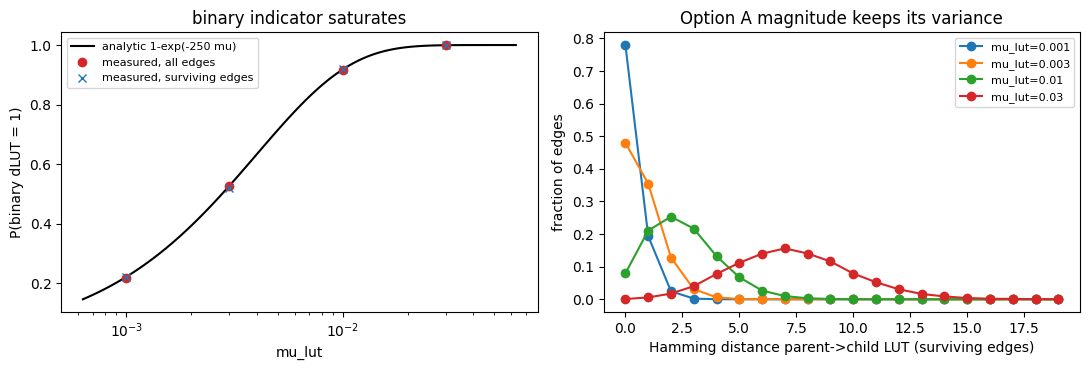

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
mus = np.array(list(edges8)); x = np.logspace(-3.2, -1.2, 100)
ax[0].plot(x, 1 - np.exp(-250 * x), 'k-', label='analytic 1-exp(-250 mu)')
ax[0].plot(mus, [(edges8[m][0] > 0).mean() for m in mus], 'o', c='C3', label='measured, all edges')
ax[0].plot(mus, [(edges8[m][0][edges8[m][2]] > 0).mean() for m in mus], 'x', c='C0', label='measured, surviving edges')
ax[0].set_xscale('log'); ax[0].set_xlabel('mu_lut'); ax[0].set_ylabel('P(binary dLUT = 1)')
ax[0].set_title('binary indicator saturates'); ax[0].legend(fontsize=8)
for m, c in zip(mus, ['C0', 'C1', 'C2', 'C3']):
    h = np.bincount(edges8[m][0][edges8[m][2]], minlength=20)[:20] / max(1, edges8[m][2].sum())
    ax[1].plot(np.arange(20), h, 'o-', c=c, label=f'mu_lut={m}')
ax[1].set_xlabel('Hamming distance parent->child LUT (surviving edges)'); ax[1].set_ylabel('fraction of edges')
ax[1].set_title('Option A magnitude keeps its variance'); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Observations.**
- *Observed in this example run (N=64, one seed per `mu_lut`, not a campaign result):* the binary dLUT indicator reproduces the recorded
  analytic saturation (0.918 at 0.01, 0.9994 at 0.03) within 0.003: measured 0.917 and 0.9992 on all edges, 0.920 and 0.9992 on surviving edges. The survival filter
  barely moves P(dLUT>0), which says survival over this window is nearly blind to *whether* the LUT changed at all.
- The Option A magnitude (Hamming distance of the 32 LUT bytes) has mean `250*mu_lut` and a spread that grows with `mu_lut`
  (sd 0.5 to 2.6), so it has variance where the binary indicator has none. Bulk LUT bytes are available with one pointer read
  (`evoca_get_lut`), so Option A is cheap at this N; no per-cell loop over `get_lut(idx)` is needed.
- The Spearman correlation between LUT-Hamming and egene-Hamming among surviving edges is ~0 (|rho| <= 0.018) at every `mu_lut` here; one of four
  permutation p-values is 0.037 (rho -0.018 at 0.001), which is not significant after four tests. That is **not** evidence of "no co-evolution": most flipped LUT bits are silent (never queried), so the
  magnitude is dominated by neutral noise, and one short window at N=64 has little power. This is exactly why the plan pairs A with
  Option F (flips restricted to queried bits, `restricted_mu`) and why an *outcome* variable (see section 4) matters.

**Directions that came out of it.** The redesign decision (which fix option) is deferred to N and recorded as **LIN-D1** in
[`ISSUES.md`](ISSUES.md); the 2026-10-15 merge of the D2 reducer changes the menu (section 4 and section 5).

## 4. 2026-10-15: lineage field + D2 per-lineage net-return reducer on `main` (new example runs)

**What is newly available.** `sim.init(N, ..., lineage=True)` records the lineage field; `get_lineage_return()` returns one row per
distinct **full-genome hash** (LUT || egene) with cumulative `intake`, `tax`, `net`, `births`, live `pop`, `first_step`, `last_step`;
`lineage_return_totals()` is the run-cumulative cross-check. (`enable_lineage()` before `init` raises; after `init`, current cells
become founders.) The reducer counts **nominal** tax; the dissipation accountant counts tax actually removed, so they differ on
tax-death steps. Tests: [`tests/notebooks/lineage-return-test.ipynb`](../../tests/notebooks/lineage-return-test.ipynb).

The H1/D3 programs want **per-lineage net-return trajectories**, **longevity vs net return**, and a comparison between an **evolving run
and a frozen-mutation control**. Examples below use the #3c regime at N=96.

### 4a. What does a hash-keyed "lineage" resolve at different `mu_lut`?

The reducer keys on the full-genome hash, so a "lineage" is a *genotype*, not a clade. Before reading trajectories, check how many cells
share each genotype. (`mu_egene = mu_egenome = 0.01`, 2000 steps, seed 2, N=96.)

In [16]:
def run_lineage(N, seed, mu_lut, mu_eg, mu_egn, egenome, T, every=25, min_births=10, mu_off_after=None):
    s = ee.build_sim(dict(REG3C, mu_lut=mu_lut, mu_egene=mu_eg, mu_egenome=mu_egn, tax_per_egene=0.0),
                     N=N, seed=seed, lineage=True, egenome=egenome)
    snaps, agg = [], []
    for i in range(T):
        s.step()
        if (i + 1) % every == 0:
            r = s.get_lineage_return()                    # refreshes pop / last_step
            snaps.append((i + 1, r[r['births'] >= min_births].copy()))
            agg.append(dict(t=i + 1, pop=int(s.get_alive().sum()), negene=mean_negene(s),
                            net_total=float(r['net'].sum()), n_lin=r.size))
    red = s.get_lineage_return()
    it, tx = s.lineage_return_totals()
    frame = rgb(s, 3)
    diss = s.get_dissipation()
    s.free()
    return dict(red=red, snaps=snaps, agg=pd.DataFrame(agg), totals=(it, tx), frame=frame, diss=diss)

t0 = time.time()
rows = []
for mu in (0.001, 0.003, 0.01, 0.03):
    r = run_lineage(96, 2, mu, 0.01, 0.01, 'uniform', 2000, every=2000)
    red = r['red']; live = red[red['pop'] > 0]
    shared = live['pop'][live['pop'] >= 2].sum() / max(1, live['pop'].sum())
    rows.append({'mu_lut': mu, 'hash-lineages ever': red.size, 'alive cells': int(live['pop'].sum()),
                 'distinct live genotypes': live.size,
                 'frac of alive cells sharing genotype': round(float(shared), 3),
                 'max births in one lineage': int(red['births'].max()),
                 'lineages with >=10 births': int((red['births'] >= 10).sum()),
                 'reducer sum(intake)-total': float(red['intake'].sum() - r['totals'][0]),
                 'reducer sum(tax)-total': float(red['tax'].sum() - r['totals'][1])})
print(f'{time.time()-t0:.1f}s')
display(pd.DataFrame(rows).set_index('mu_lut').T)

4.3s


mu_lut,0.001,0.003,0.010,0.030
hash-lineages ever,65031.000,89863.00,125504.000,132708.000
alive cells,836.000,365.00,2965.000,2768.000
distinct live genotypes,516.000,336.00,2839.000,2767.000
frac of alive cells sharing genotype,0.589,0.14,0.081,0.001
max births in one lineage,3071.000,1766.00,320.000,2.000
lineages with >=10 births,535.000,67.00,4.000,0.000
reducer sum(intake)-total,0.000,0.00,0.000,0.000
reducer sum(tax)-total,0.000,0.00,0.000,0.000


In [17]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = ee.build_sim(dict(REG3C, mu_lut=0.003, mu_egene=0.01, mu_egenome=0.01, tax_per_egene=0.0),
#                  N=256, seed=2, lineage=True)   # mu_lut in {0.001, 0.003, 0.01, 0.03}
# run_with_controls(s, cell_px=2, colormode=3, probes={'activity': True, 'ts': True})

*Observed in this example run (N=96, seed 2, not a campaign result):* at `mu_lut=0.001` 59% of live cells share a genotype and 535 lineages reach 10 births
(max 3,071); at 0.003, 14% and 67 (max 1,766); at 0.01, 8% and 4 (max 320); at 0.03, 0.1% and none (max 2). The live population at t=2000 varies
(365 to 2,965 cells) because the population boom-busts in this regime, so the snapshot catches different phases. At productive `mu_lut` the per-hash net
return is therefore a **per-individual** lifetime net return, not a clade property. This is the lineage-field analog of the #8 saturation: mutation outruns
the genotype key. For H1 at `mu_lut >= 0.01` the lineage unit should be a clade (roll up along `parent_id` chains) or a phenotype-level key. The completeness
cross-check (reducer sums equal `lineage_return_totals`) holds to float precision in every row.

### 4b. Per-lineage net-return trajectories and longevity vs net return: evolving run vs frozen-mutation control

- **Evolving run:** `mu_lut=0.0003, mu_egene=mu_egenome=0.003` from uniform egenome on GoL (mutation slow enough that large lineages exist to follow; at `mu_lut >= 0.003` the top lineages are gone within a few hundred steps, see 4a).
- **Frozen-mutation control:** all mutation rates 0, egenomes randomized at start (`egenome='random'`), so a standing library of fixed genotypes competes
  by selection alone (no new variation). Same regime, size, and seed.

N=96, 3000 steps, `get_lineage_return()` sampled every 25 steps (rows with >= 10 births kept). Top 8 lineages by final births are drawn.
Per-capita rate = d(net)/(dt * mean pop) between samples.

1.9s


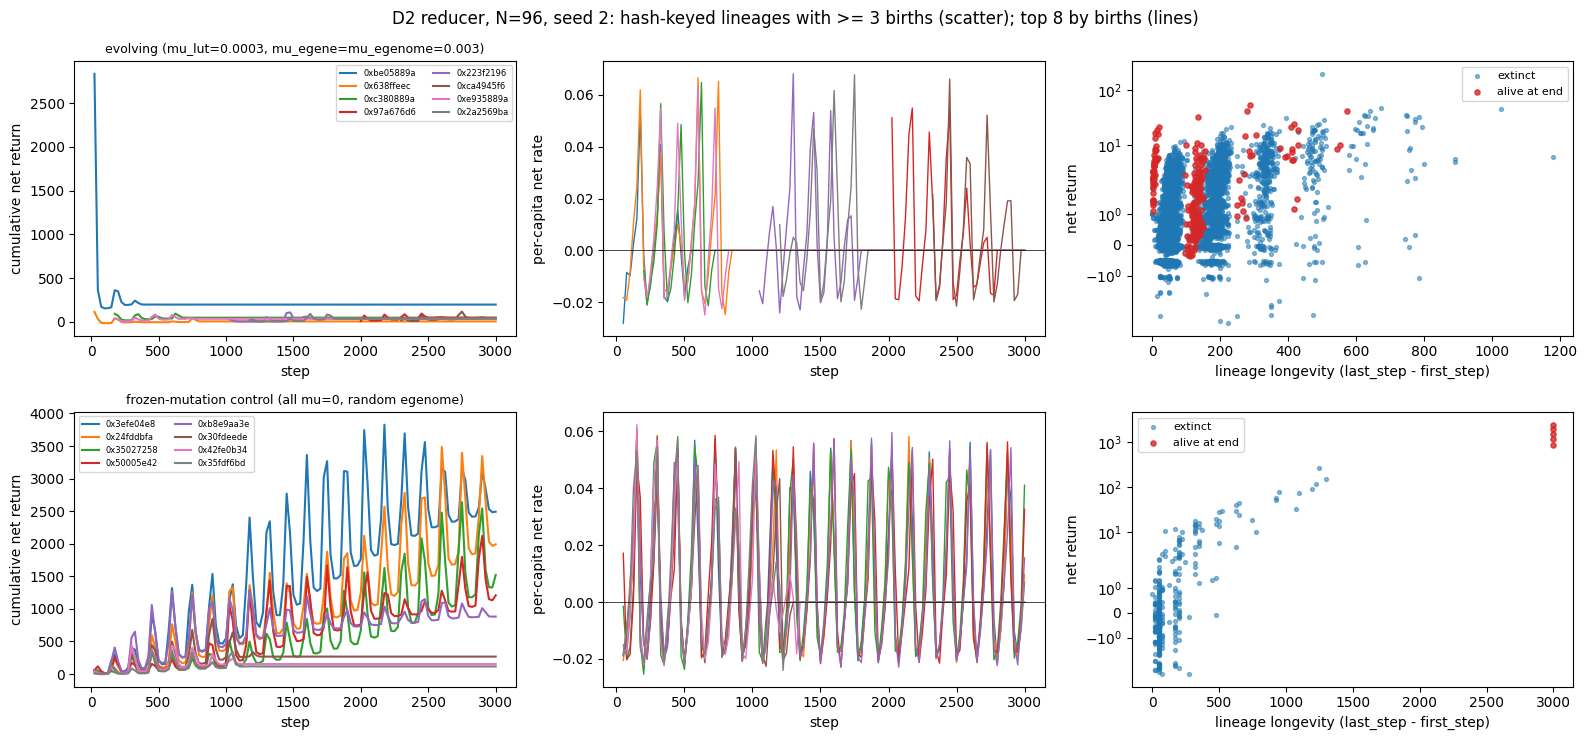

,hash-lineages ever,with >=3 births,final pop,"Spearman(longevity, net), >=3 births",frac with net<0,total intake,"tax, reducer (nominal)","tax, dissipation accountant (actual)",food overflow (accountant),genotypes alive at end,source (food_inc * N^2 * T)
run,,,,,,,,,,,
evolving,32356,18697,924,0.395,0.554,352853,343261,341629,63146,279,414720
control,681,332,579,0.562,0.530,352835,343538,341937,63162,5,414720


In [18]:
t0 = time.time()
evo = run_lineage(96, 2, 0.0003, 0.003, 0.003, 'uniform', 3000)
ctl = run_lineage(96, 2, 0.0, 0.0, 0.0, 'random', 3000)
print(f'{time.time()-t0:.1f}s')

def trajectories(r, top=8):
    red = r['red']
    ids = red['hash'][np.argsort(red['births'].astype(np.int64))[::-1][:top]]
    out = {}
    for h in ids:
        tt, net, pop = [], [], []
        for t, sn in r['snaps']:
            m = sn['hash'] == h
            if m.any():
                tt.append(t); net.append(float(sn['net'][m][0])); pop.append(int(sn['pop'][m][0]))
        out[int(h)] = (np.array(tt), np.array(net), np.array(pop))
    return out

fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for row, (name, r) in enumerate((('evolving (mu_lut=0.0003, mu_egene=mu_egenome=0.003)', evo), ('frozen-mutation control (all mu=0, random egenome)', ctl))):
    tr = trajectories(r)
    for k, (h, (tt, net, pop)) in enumerate(tr.items()):
        ax[row, 0].plot(tt, net, c=f'C{k}', label=f'0x{h:08x}')
        if len(tt) > 2:
            rate = np.diff(net) / (np.diff(tt) * np.maximum(1, 0.5 * (pop[1:] + pop[:-1])))
            ax[row, 1].plot(tt[1:], rate, c=f'C{k}', lw=1)
    ax[row, 0].set_ylabel('cumulative net return'); ax[row, 0].set_title(name, fontsize=9)
    ax[row, 1].set_ylabel('per-capita net rate'); ax[row, 1].axhline(0, c='k', lw=0.5)
    red = r['red']; k = red['births'] >= 3
    dur = (red['last_step'].astype(float) - red['first_step'])[k]
    alive = (red['pop'] > 0)[k]
    ax[row, 2].scatter(dur[~alive], red['net'][k][~alive], s=8, c='C0', alpha=0.5, label='extinct')
    ax[row, 2].scatter(dur[alive], red['net'][k][alive], s=14, c='C3', alpha=0.8, label='alive at end')
    ax[row, 2].set_xlabel('lineage longevity (last_step - first_step)'); ax[row, 2].set_ylabel('net return')
    ax[row, 2].set_yscale('symlog'); ax[row, 2].legend(fontsize=8)
    ax[row, 0].legend(fontsize=6, ncol=2); ax[row, 0].set_xlabel('step'); ax[row, 1].set_xlabel('step')
fig.suptitle('D2 reducer, N=96, seed 2: hash-keyed lineages with >= 3 births (scatter); top 8 by births (lines)')
fig.tight_layout(); plt.show()

rows = []
for name, r in (('evolving', evo), ('control', ctl)):
    red = r['red']; k = red['births'] >= 3
    dur = (red['last_step'].astype(float) - red['first_step'])[k]
    net = red['net'][k]
    from scipy.stats import spearmanr as _sp
    rows.append({'run': name, 'hash-lineages ever': red.size, 'with >=3 births': int(k.sum()),
                 'final pop': int(r['agg']['pop'].iloc[-1]),
                 'Spearman(longevity, net), >=3 births': round(float(_sp(dur, net)[0]), 3) if k.sum() > 3 else None,
                 'frac with net<0': round(float((net < 0).mean()), 3) if k.sum() else None,
                 'total intake': round(r['totals'][0]), 'tax, reducer (nominal)': round(r['totals'][1]),
                 'tax, dissipation accountant (actual)': round(r['diss']['tax_cum']),
                 'food overflow (accountant)': round(r['diss']['overflow_cum']),
                 'genotypes alive at end': int((red['pop'] > 0).sum()),
                 'source (food_inc * N^2 * T)': round(0.015 * 96**2 * 3000)})
display(pd.DataFrame(rows).set_index('run'))

In [19]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = ee.build_sim(dict(REG3C, mu_lut=0.0003, mu_egene=0.003, mu_egenome=0.003, tax_per_egene=0.0),
#                  N=256, seed=2, lineage=True)   # the evolving arm; control: all mu = 0, egenome='random'
# run_with_controls(s, cell_px=2, colormode=3, probes={'activity': True, 'eg_activity': True, 'ts': True})

**Observations** (*observed in this example run, N=96, seed 2, one run per arm; not a campaign result*):
- **Boom-bust, not a saturated lattice.** Under the standard rule this regime oscillates: the per-capita net rate of the top lineages swings between about -0.02 and
  +0.06 per step with a period of ~150 steps, and in the control all top genotypes swing **in phase**. Final populations are 924 (evolving) and 579 (control).
  Total intake is 352,853 and 352,835, 85% of the food source (`food_inc*N^2*T` = 414,720); the accountant's overflow (regrowth falling on full sites)
  is 63,146 and 63,162. Coexisting genotypes share the same per-capita time course, so raw net return still measures the shared cycle and a lineage's share
  of it, not genotype fitness. Adaptive-vs-drift claims must compare net return **against a neutral expectation** (shadow or matched null), as the checkpoint
  section H step 2 says.
- **Nominal vs actual tax agree.** Reducer tax (nominal) exceeds the tax the dissipation accountant actually removed by 0.5% (343,261 vs 341,629 evolving; 343,538 vs
  341,937 control). The 20-23% gap seen before was a legacy-rule effect (overdraw drained private food, so dying cells could not pay); see LIN-D3.
- **Genotype lineages.** The evolving run has 32,356 hash-lineages in 3000 steps and 279 genotypes alive at the end. The founder genotype leads early and its
  cumulative net is flat from about step 400; later top lineages are each active for several hundred steps (per-capita panel). The control has 681 lineages and
  5 genotypes alive at the end, so selection alone does not reduce it to one winner here.
- **Longevity vs net return is positive in both arms.** Spearman(longevity, net) is +0.40 (evolving) and +0.56 (control) for lineages with >= 3 births. Longevity
  is quantized by the 25-step sampling interval, because `last_step` is only as current as the last `lineage_return_update()`/`get_lineage_return()` call. A neutral
  lineage that is early and large also shows long life and large |net|, so the scatter alone cannot separate adaptation from drift.

### 4c. D3 preview: aggregate per-capita net return alongside mean Negene (no detector built)

The punctuation hypothesis (checkpoint section D, N's 2026-07-19 reply on section D) is a dip-then-staircase in lineage net return
when a lineage gains an egene. D3 (detector) is **not** built. As a feasibility check only: in the evolving run, plot mean Negene and the
population-wide per-capita net rate (d(sum net)/dt / pop) on one time axis.

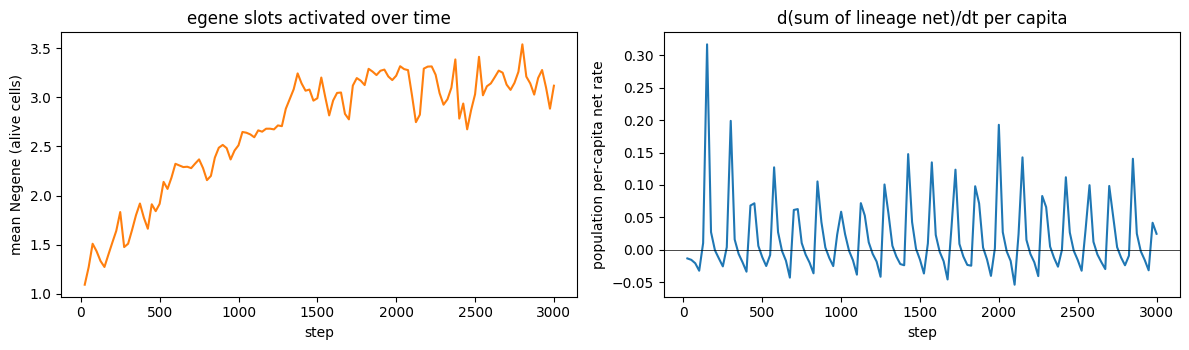

mean Negene: start 1.09, max 3.54, end 3.12


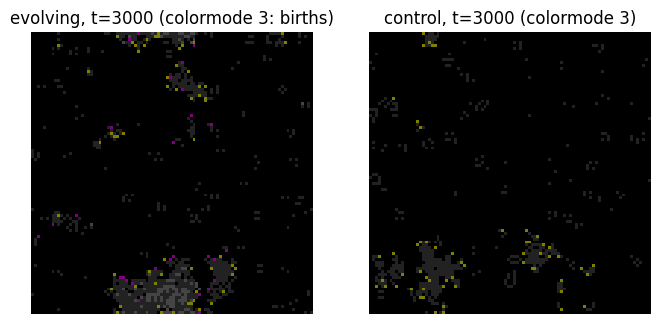

In [20]:
a = evo['agg']
rate = np.gradient(a.net_total.values, a.t.values) / np.maximum(1, a['pop'].values)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(a.t, a.negene, c='C1'); ax[0].set_ylabel('mean Negene (alive cells)'); ax[0].set_xlabel('step')
ax[0].set_title('egene slots activated over time')
ax[1].plot(a.t, rate, c='C0'); ax[1].set_ylabel('population per-capita net rate'); ax[1].set_xlabel('step')
ax[1].axhline(0, c='k', lw=0.5); ax[1].set_title('d(sum of lineage net)/dt per capita')
fig.tight_layout(); plt.show()
print('mean Negene: start %.2f, max %.2f, end %.2f' % (a.negene.iloc[0], a.negene.max(), a.negene.iloc[-1]))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(evo['frame'], interpolation='nearest'); ax[0].set_title('evolving, t=3000 (colormode 3: births)'); ax[0].axis('off')
ax[1].imshow(ctl['frame'], interpolation='nearest'); ax[1].set_title('control, t=3000 (colormode 3)'); ax[1].axis('off')
plt.show()

*Observed in this example run:* mean Negene rises from ~1.1 to ~3.2 by step ~1400 and then wanders between ~2.7 and ~3.5 (end 3.12), so there is no clean single staircase
to detect at the population level. The population-level net rate oscillates with the population cycle (spikes to 0.1-0.3), so a staircase in per-lineage net
return would have to be extracted at the lineage level (a lineage that *gains* an egene slot, tracked across the change), not from population averages. That
requires knowing, per lineage, when Negene stepped: the reducer keys on the full-genome hash, so a Negene change creates a **new** hash row; the detector must
link parent hash to child hash (the `lineage_parent_hash` field supplies the parent's hash for each newborn, so the link exists but is not yet exposed as a
table). This is the main piece of D3 dev work.

## 5. Current state and directions (2026-10)

**Where things stand (standard model, 2026-10-23).**
- **Campaigns #3 and #3c, rescanned under the standard rule:** the recorded co-dependence does not survive. In #3, freezing the LUT at GoL (3b) costs nothing:
  extinction 2/144 vs 3/144 and mean `eg_excess_pc_slope` 24.0 vs 22.6 (3a). In #3c, frozen GoL (B) is viable in 10/10 and the GoL anchors carry late-window
  egene excess (B +0.97, B' +2.44) as large as the evolved-substrate arms (C +1.35, A -0.06). Co-evolving the rule still beats freezing it from the same substrate,
  modestly and consistently (paired C-A > 0 in 27/30, mean +0.44). The `dyn_excess_pc` frozen-rich-substrate artifact does not appear (0/30 A runs).
  The recorded results (3a >> 3b, GoL-substrate death, the dyn artifact) are legacy-rule phenomena: a legacy rerun with today's code reproduces them (last section).
  **The scientific question (adaptive co-evolution vs joint drift) is still open**: the only surviving signal of coupling is the small C-over-A advantage,
  and the direct test (#8) has no data.
- **Available since the 2026-10-15 merges (lineage field + D2 reducer):** D3 (punctuation detector) and H1 (adaptive-vs-drift program) can start, and the #8 redesign
  can use a per-lineage fitness outcome. Section 4 shows the reducer works at N=96 and that it is **genotype-keyed**.
- **What the example runs add (single seed, small N, not campaign results):** (i) the #3c regime (`m_scale` 3, `food_inc` 0.015, `tax` 0.035) boom-busts under the
  standard rule (period ~150-350 steps at N=96); (ii) the shared-substrate fork is bit-identical at small N; (iii) the neutral shadow no longer perturbs the real run
  (LIN-Q4); (iv) the binary dLUT indicator reproduces the analytic saturation, and the Hamming magnitude does not saturate; (v) at `mu_lut >= 0.01`, hash-keyed
  lineages are near-singletons, so H1 at productive `mu_lut` needs clade roll-up; (vi) coexisting genotypes share the same per-capita net-rate time course, so raw net
  return must be compared to a neutral expectation; the reducer's nominal tax now agrees with the tax actually removed to 0.5%.
- **Outstanding decisions, see [`ISSUES.md`](ISSUES.md):** LIN-D1 (#8 redesign option), LIN-D2 (lineage unit for H1 at productive `mu_lut`).

## Legacy rule (`food_cap=0`): results that depend on it

Everything in this section uses the **legacy uncapped mouthful**, which is not part of the model: a cell's mouthful could exceed what its site held, drive `F`
negative and drain the next eater's private food (defect A9, fixed 2026-10-15 by `food_cap=1`). Campaigns #3 and #3c ran under it (every row has `m_scale` 1.5-3,
where the cap can bind), and so did the example runs stored in this notebook before 2026-10-23. Nothing in the main thread depends on this section.

Three columns: *recorded* (the May scans), *legacy now* (today's code, `food_cap=0`: [`Scans/2026-10-23_legacy_now_subset`](Scans/2026-10-23_legacy_now_subset/notes.md),
a subset of 24 #3 rows and 10 #3c runs) and *standard* (the rescans the main thread uses). Recorded vs legacy-now is the code change since May (mainly the shadow's
own RNG stream); legacy-now vs standard is the rule.

In [21]:
o3 = pd.read_csv(SCANS / '2026-05-17_pure_evo_egene_on_winners' / 'results.csv').set_index('config_idx')
oc = pd.read_csv(SCANS / '2026-05-19_3c_coevolution_substrate' / 'results.csv')
LN = pd.read_csv(SCANS / '2026-10-23_legacy_now_subset' / 'results.csv')
s3 = d3.set_index('config_idx')

# (1) whole scans, recorded (legacy) vs standard rescan
print('Campaign #3 by mode: recorded (legacy) vs standard')
display(pd.concat({src: d.groupby('mode').agg(extinct=('extinct', 'sum'), eg_slope_mean=('eg_excess_pc_slope', 'mean'),
                                               eg_slope_median=('eg_excess_pc_slope', 'median'), density=('alive_density_mean', 'mean'))
                   for src, d in (('recorded', o3), ('standard', s3))}, axis=1).round(2))
print('#3c by arm: recorded (legacy) vs standard')
agg3c = dict(extinct=('extinct', 'sum'), eg_slope=('eg_excess_pc_slope', 'mean'), eg_slope_late=('eg_excess_pc_slope_late', 'mean'),
             dyn_slope_median=('dyn_excess_pc_slope', 'median'), min_pop=('min_pop', 'mean'), final_pop=('final_pop', 'mean'))
display(pd.concat({src: d.groupby('arm').agg(**agg3c).reindex(['A', 'C', 'B', "B'"]) for src, d in (('recorded', oc), ('standard', c3))}, axis=1).round(2))
for src, d in (('recorded', oc), ('standard', c3)):
    a = d[d.arm == 'A'].set_index(['seed', 'param_mu_lut_p1']); c = d[d.arm == 'C'].set_index(['seed', 'param_mu_lut_p1'])
    p = c.eg_excess_pc_slope - a.eg_excess_pc_slope
    print(f'{src:9s} paired C-A eg slope > 0 in {int((p > 0).sum())}/{len(p)}, mean {p.mean():+.2f};  '
          f'A dyn slope > 50 in {int((a.dyn_excess_pc_slope > 50).sum())}/{len(a)}, median {a.dyn_excess_pc_slope.median():+.1f}')

# (2) the legacy-now subset: recorded / legacy now / standard, row by row
l3 = LN[LN.src == '3'].set_index('config_idx')
print('#3 subset (bases 5, 7, 11): extinct runs and mean eg_excess_pc_slope by mode')
display(pd.DataFrame({(m, col): d.loc[l3.index, m].groupby(l3['mode']).agg('sum' if m == 'extinct' else 'mean')
                      for m in ('extinct', 'eg_excess_pc_slope') for col, d in (('recorded', o3), ('legacy now', l3), ('standard', s3))}).round(2))
k = ['arm', 'seed', 'param_mu_lut_p1']
lc = LN[LN.src == '3c']
cols = ['extinct', 'min_pop', 'eg_excess_pc_slope_late', 'dyn_excess_pc_slope']
tab = pd.concat({src: d.merge(lc[k], on=k).set_index(k)[cols] for src, d in (('recorded', oc), ('legacy now', lc), ('standard', c3))}, axis=1)
print('#3c subset: B seeds 0-3, A/C at phase-1 mu_lut 0.01 seeds 0-2')
display(tab.round(2))

Campaign #3 by mode: recorded (legacy) vs standard


recorded                                       standard                \
      extinct eg_slope_mean eg_slope_median density  extinct eg_slope_mean   
mode                                                                         
3a         17         17.48           14.23    0.19        3         22.61   
3b         66          1.74           -0.02    0.18        2         23.96   

                              
     eg_slope_median density  
mode                          
3a             10.62    0.23  
3b             15.35    0.22

#3c by arm: recorded (legacy) vs standard


recorded                                                              \
     extinct eg_slope eg_slope_late dyn_slope_median   min_pop final_pop   
arm                                                                        
A          0    -0.38          0.03           249.20  21723.47  48949.30   
C          0     0.24          1.06             0.53   5569.23  27093.27   
B         10     0.00          0.00             0.00      0.00      0.00   
B'         0    -0.00         -0.00             0.00  31749.60  55639.00   

    standard                                                             
     extinct eg_slope eg_slope_late dyn_slope_median  min_pop final_pop  
arm                                                                      
A          0    -1.63         -0.06            -1.36  8029.67  28949.73  
C          0    -1.19          1.35             1.09  6725.03  13822.13  
B          0     0.69          0.97             0.00  2496.00  18314.40  
B'         0     1.44          2.44             0.00  2568.40   9960.70

recorded  paired C-A eg slope > 0 in 22/30, mean +0.62;  A dyn slope > 50 in 21/30, median +249.2
standard  paired C-A eg slope > 0 in 27/30, mean +0.44;  A dyn slope > 50 in 0/30, median -1.4
#3 subset (bases 5, 7, 11): extinct runs and mean eg_excess_pc_slope by mode


extinct                     eg_excess_pc_slope                    
     recorded legacy now standard           recorded legacy now standard
mode                                                                    
3a          0          0        0               8.13       6.63     0.69
3b         12         12        0              -1.97      -0.87     4.01

#3c subset: B seeds 0-3, A/C at phase-1 mu_lut 0.01 seeds 0-2


recorded                                  \
                          extinct min_pop eg_excess_pc_slope_late   
arm seed param_mu_lut_p1                                            
B   0    0.00                True       0                    0.00   
    3    0.00                True       0                    0.00   
    1    0.00                True       0                    0.00   
    2    0.00                True       0                    0.00   
A   2    0.01               False   40921                   -0.00   
C   2    0.01               False    7406                   -0.54   
A   0    0.01               False   41821                   -0.00   
C   0    0.01               False    3726                    0.56   
A   1    0.01               False   36615                    0.00   
C   1    0.01               False   10032                    1.32   

                                             legacy now          \
                         dyn_excess_pc_slope    extinct min_pop   
arm seed param_mu_lut_p1                                          
B   0    0.00                          -0.00       True       0   
    3    0.00                           0.00       True       0   
    1    0.00                           0.00       True       0   
    2    0.00                           0.00       True       0   
A   2    0.01                         723.06      False   41046   
C   2    0.01                           0.57      False    9135   
A   0    0.01                         675.28      False   40238   
C   0    0.01                          -1.91      False    4604   
A   1    0.01                         424.80      False   32339   
C   1    0.01                           0.52      False    2530   

                                                                     standard  \
                         eg_excess_pc_slope_late dyn_excess_pc_slope  extinct   
arm seed param_mu_lut_p1                                                        
B   0    0.00                               0.00                0.00    False   
    3    0.00                               0.00                0.00    False   
    1    0.00                               0.00                0.00    False   
    2    0.00                               0.00                0.00    False   
A   2    0.01                               0.00              484.24    False   
C   2    0.01                               0.84                0.39    False   
A   0    0.01                               0.00              412.68    False   
C   0    0.01                              -6.17               -0.11    False   
A   1    0.01                               0.00                6.72    False   
C   1    0.01                              -6.27                7.21    False   

                                                                              
                         min_pop eg_excess_pc_slope_late dyn_excess_pc_slope  
arm seed param_mu_lut_p1                                                      
B   0    0.00               3057                    1.59                0.00  
    3    0.00               2952                    0.32                0.00  
    1    0.00               2087                   -0.14                0.00  
    2    0.00               2145                    9.71                0.00  
A   2    0.01               7543                    0.07               -2.06  
C   2    0.01               6550                   -0.06                1.63  
A   0    0.01               4839                    0.63               -0.61  
C   0    0.01               6763                    2.00                0.50  
A   1    0.01               9481                   -0.91               -1.27  
C   1    0.01               7831                    1.44               -1.91

**Observations.**
- **The rule, not the code drift, made the recorded headlines.** In the subset, the legacy rule with today's code reproduces the recorded outcomes: all 12 frozen-GoL
  3b rows go extinct (recorded 12/12, standard 0/12), all 4 B runs go extinct (recorded 4/4, standard 0/4), and 2 of 3 A runs show the `dyn_excess_pc` artifact
  (slopes +413, +7, +484; recorded +675, +425, +723; standard -0.6, -1.3, -2.1).
- **Campaign #3, recorded vs standard:** 3b extinction 66/144 -> 2/144; 3a 17/144 -> 3/144. Mean `eg_excess_pc_slope` 3a 17.5 -> 22.6, 3b 1.7 -> 24.0.
  The recorded "3a >> 3b" co-dependence (and the 9/12-bases advantage in the devlog) becomes 3a ~ 3b (3a ahead on 5/12).
- **#3c, recorded vs standard:** B 10/10 extinct -> 0/10. B and B' egene excess ~0 -> positive (late window +0.97, +2.44). Paired C-A > 0 in 22/30 (mean +0.62)
  -> 27/30 (mean +0.44): the one recorded co-evolution signal survives. The A-arm dyn artifact (21/30 > 50, median +249) -> none.
- **Mechanism, as far as these columns show:** under the legacy rule at `m_scale` 1.5-3, frozen GoL dies out and the evolved-substrate arms sit near saturation
  (A min_pop ~40,000 at N=256); under the cap the same configs survive and boom-bust. The artifact needs the saturated frozen-rich population, so it goes with it.
  Why the overdraw kills GoL specifically is not tested here.
- **Example runs stored before 2026-10-23** were legacy-rule runs with the pre-2026-10-15 shadow RNG coupling (e.g. 3b cfg253 extinct at N=128; a saturated N=96 lattice
  with intake equal to the food source; reducer tax 20-23% above the accountant's). They are superseded by the outputs above and not reproduced here.

In [22]:
print(f'notebook wall time: {time.time()-T_NOTEBOOK:.0f}s')

notebook wall time: 32s
